In [1]:
import socket, requests

try:
    print("DNS:", socket.getaddrinfo("web.archive.org", 443, proto=socket.IPPROTO_TCP)[0][4])
except Exception as e:
    print("DNS FAILED:", e)

for u in ["https://example.com", "https://archive.org/",
          "http://web.archive.org/", "https://web.archive.org/"]:
    try:
        print(requests.get(u, timeout=15).status_code, u)
    except Exception as e:
        print("FAILED", type(e).__name__, u)

DNS: ('207.241.237.3', 443)
200 https://example.com
200 https://archive.org/
200 http://web.archive.org/
200 https://web.archive.org/


In [2]:
"""
Compare an entry in typepad_archives.txt (Movable Type export format)
with its captures on the Wayback Machine.
 
Paste into notebook cells, or run as a module.
"""
import re
import time
import html
import unicodedata
 
import requests
from bs4 import BeautifulSoup
 
SESSION = requests.Session()
SESSION.headers["User-Agent"] = "delong-archive-comparison/0.1 (research; your-email@berkeley.edu)"
PAUSE = 1.0  # seconds between Wayback requests; be polite
 
 
# ---------------------------------------------------------------- parsing
def split_entries(text):
    """Entries are separated by a line of exactly 8 dashes."""
    return [e for e in re.split(r"^-{8}\s*$", text, flags=re.M) if e.strip()]
 
 
def parse_entry(entry):
    """
    Movable Type format: header lines (KEY: value), then sections separated by
    a line of exactly 5 dashes. Each section starts with 'BODY:', 'EXTENDED BODY:', etc.
    Splitting on the section separators avoids the problem of a body line such as
    'NASA GISS:' being mistaken for a new field.
    """
    head, *sections = re.split(r"^-----\s*$", entry, flags=re.M)
 
    meta = {}
    for line in head.strip().splitlines():
        if ":" in line:
            k, v = line.split(":", 1)
            meta[k.strip().upper()] = v.strip()
 
    fields = {}
    for sec in sections:
        m = re.match(r"\s*(BODY|EXTENDED BODY|EXCERPT|KEYWORDS):[ \t]*\n?(.*)", sec, flags=re.S)
        if m:
            fields[m.group(1)] = m.group(2).strip()
 
    return {
        "title": meta.get("TITLE", ""),
        "status": meta.get("STATUS", ""),
        "basename": meta.get("BASENAME", ""),
        "url": meta.get("UNIQUE URL", ""),
        "date": meta.get("DATE", ""),
        # The page shows body + extended body, so compare against both
        "body": (fields.get("BODY", "") + "\n" + fields.get("EXTENDED BODY", "")).strip(),
    }
 
 
# ---------------------------------------------------------------- text cleanup
def html_to_text(markup):
    soup = BeautifulSoup(markup, "html.parser")
    for t in soup(["script", "style", "noscript"]):
        t.decompose()
    return soup.get_text(" ", strip=True)
 
 
def normalize(text):
    """Lowercase, unescape entities, unify quotes, drop punctuation, collapse whitespace.
    Dropping punctuation makes 'syndicate :' and 'syndicate:' compare equal, which
    plain get_text(' ') otherwise turns into spurious mismatches."""
    text = html.unescape(text)
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = text.replace("\u201c", '"').replace("\u201d", '"')
    text = re.sub(r"[^\w\s]", " ", text.lower())
    return re.sub(r"\s+", " ", text).strip()
 
 
# ---------------------------------------------------------------- similarity
def shingles(text, n=5):
    w = text.split()
    if not w:
        return set()
    return {" ".join(w[i:i + n]) for i in range(max(len(w) - n + 1, 1))}
 
 
def containment(archive_text, wayback_text, n=5):
    """Fraction of the archive entry's word-5-grams that appear in the Wayback page.
    Unlike SequenceMatcher.ratio(), this is not diluted by the sidebar/nav text that
    surrounds the post on the live page, and unlike fixed 20-word chunks it doesn't
    depend on where the chunk boundaries happen to fall."""
    sa, sb = shingles(archive_text, n), shingles(wayback_text, n)
    return len(sa & sb) / len(sa) if sa else None
 
 
def verdict(c):
    if c is None:
        return "UNCERTAIN (archive body empty)"
    if c >= 0.98:
        return "SAME"
    if c >= 0.85:
        return "LIKELY SAME (review)"
    if c >= 0.50:
        return "PARTIAL (review)"
    return "DIFFERENT"
 
 
# ---------------------------------------------------------------- Wayback
def list_captures(url):
    r = SESSION.get(
        "https://web.archive.org/cdx/search/cdx",
        params={"url": url, "output": "json",
                "filter": "statuscode:200", "collapse": "digest"},
        timeout=60,
    )
    r.raise_for_status()
    if not r.text.strip():
        return []
    rows = r.json()
    if len(rows) < 2:
        return []
    return [dict(zip(rows[0], row)) for row in rows[1:]]
 
 
def fetch_capture(cap):
    # 'id_' returns the original HTML without the Wayback toolbar or rewritten links
    u = f"https://web.archive.org/web/{cap['timestamp']}id_/{cap['original']}"
    r = SESSION.get(u, timeout=60)
    r.raise_for_status()
    return r.text, u
 
 
def candidate_urls(parsed):
    """URLs under which this entry may have been archived. The export lists the
    current bradford-delong.com address; the old TypePad address is a guess
    (check the real path against the CDX results)."""
    urls = [parsed["url"]] if parsed["url"] else []
    m = re.match(r"(\d\d)/\d\d/(\d{4})", parsed["date"])
    if m and parsed["basename"] and int(m.group(2)) <= 2020:  # dates like 2036/2100/2200 are placeholders
        mm, yyyy = m.groups()
        urls.append(f"http://delong.typepad.com/sdj/{yyyy}/{mm}/{parsed['basename']}.html")
    return urls
 
 
def compare_entry(entry_text, max_captures=5):
    parsed = parse_entry(entry_text)
    archive_clean = normalize(html_to_text(parsed["body"]))
 
    best = {"title": parsed["title"], "score": None, "verdict": "NO CAPTURE FOUND",
            "capture": None, "n_captures": 0}
 
    for url in candidate_urls(parsed):
        caps = list_captures(url)
        time.sleep(PAUSE)
        best["n_captures"] += len(caps)
 
        # most recent captures first; the best-matching capture counts
        for cap in reversed(caps[-max_captures:]):
            try:
                page_html, fetched_url = fetch_capture(cap)
            except requests.HTTPError as e:
                best.setdefault("fetch_errors", []).append(f"{cap['timestamp']}: {e}")
                time.sleep(PAUSE)
                continue  # listed capture couldn't be served; try the next one
            time.sleep(PAUSE)
            score = containment(archive_clean, normalize(html_to_text(page_html)))
            if score is not None and (best["score"] is None or score > best["score"]):
                best.update(score=score, verdict=verdict(score), capture=fetched_url)
 
    return best
 
 
# ---------------------------------------------------------------- example use
if __name__ == "__main__":
    with open("typepad_archives.txt", "r") as f:
        entries = split_entries(f.read())
 
    published = [e for e in entries if re.search(r"^STATUS:\s*Publish", e, flags=re.M)]
    normal = [e for e in published if "TITLE: NOTEBOOK:" not in e]
 
    ENTRY_INDEX = 0  # change this to try a different entry
 
    entry = normal[ENTRY_INDEX]
 
    # Step (a): parse one entry from the archive file
    parsed = parse_entry(entry)
    print("--- PARSED ENTRY ---")
    for k in ("title", "status", "basename", "url", "date"):
        print(f"{k}: {parsed[k]}")
    print(f"body (first 300 chars): {parsed['body'][:300]}")
 
    # Steps (b) and (c): find it on the Wayback Machine and compare
    print("\n--- WAYBACK COMPARISON ---")
    result = compare_entry(entry)
    for k, v in result.items():
        print(f"{k}: {v}")

--- PARSED ENTRY ---
title: Global Warming
status: Publish
basename: global-warming
url: https://www.bradford-delong.com/global-warming.html
date: 01/01/2036 05:01:00 PM
body (first 300 chars): <ul>
<li><p><em><a href="https://www.bradford-delong.com/2019/01/dealing-with-global-warming-needs-a-carbon-tax-starting-now.html">Dealing with Global Warming Needs a Carbon Tax Starting Now</a></em>: It would have been smart to do it 26 years ago, when Al Gore was first pushing it—and we got it thr

--- WAYBACK COMPARISON ---
title: Global Warming
score: 1.0
verdict: SAME
capture: https://web.archive.org/web/20200807153536id_/https://www.bradford-delong.com/global-warming.html
n_captures: 7


In [3]:
parsed = parse_entry(entry)
archive_text = html_to_text(parsed["body"])
page_text = html_to_text(SESSION.get(result["capture"], timeout=60).text)

key = "carbon tax starting now"
for name, t in [("ARCHIVE", archive_text), ("WAYBACK", page_text)]:
    i = t.lower().find(key)
    print(name, "->", t[max(0, i - 50): i + 300], "\n")

print("Exact substring match (no normalization):", archive_text in page_text)

ARCHIVE -> Dealing with Global Warming Needs a Carbon Tax Starting Now : It would have been smart to do it 26 years ago, when Al Gore was first pushing it—and we got it through the House and fell short by two votes in the Senate... #globalwarming 2019-11-17 Tweed Jackets and Natural Disasters: No Longer Fresh at Project Syndicate : We as a globe 

WAYBACK -> lobal Warming Dealing with Global Warming Needs a Carbon Tax Starting Now : It would have been smart to do it 26 years ago, when Al Gore was first pushing it—and we got it through the House and fell short by two votes in the Senate... #globalwarming 2019-11-17 Tweed Jackets and Natural Disasters: No Longer Fresh at Project Syndicate : We as a globe 

Exact substring match (no normalization): True


5798 published, non-NOTEBOOK entries available
Resuming: 101 entries already in comparison_results.csv

=== Verdict counts ===


,entries
verdict,
SAME,100
ERROR,1



=== All results (lowest scores first) ===


,title,date,score,verdict,n_captures,error
0,NaN,07/06/2018 11:14:30 AM,NaN,ERROR,0,404 Client Error: NOT FOUND for url: https://w...
1,NaN,11/07/2017 01:37:09 PM,1.0,SAME,2,NaN
2,NaN,12/27/2019 04:15:32 PM,1.0,SAME,4,NaN
3,DeLongToday: Warning Clip from Last Week,10/05/2020 01:22:18 PM,1.0,SAME,6,NaN
4,NaN,04/21/2019 07:11:46 PM,1.0,SAME,6,NaN
...,...,...,...,...,...,...
96,"Procrastination for October 5, 2017...",10/05/2017 02:25:20 PM,1.0,SAME,2,NaN
97,"August 16, 2019: Weekly Forecasting Update",08/16/2019 09:57:12 AM,1.0,SAME,6,NaN
98,PROJECT SYNDICATE: Is þe US Economy Recovering...,05/05/2021 11:41:44 AM,1.0,SAME,4,NaN
99,NaN,01/25/2019 09:20:41 AM,1.0,SAME,5,NaN



Scored 100 of 101 entries | mean 1.000 | median 1.000 | min 1.000


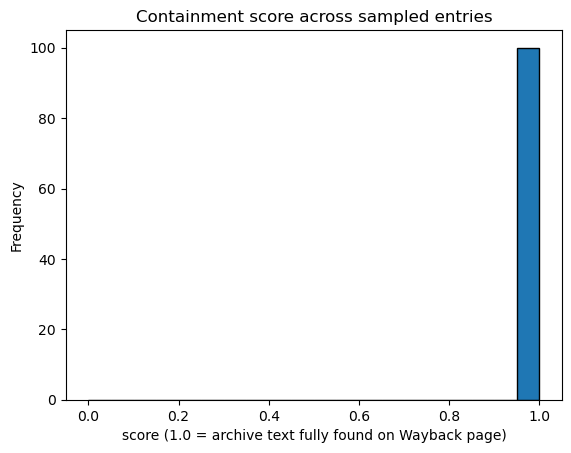

In [4]:
import os
import random
import re
import time
 
import pandas as pd
from IPython.display import display
 
# ---------------------------------------------------------------- settings
BATCH_SIZE = 20          # how many entries to test (each takes roughly 5-15 seconds)
MAX_CAPTURES = 2         # captures checked per entry; lower = faster
SEED = 42                # same seed = same sample, so results are repeatable
OUT_CSV = "comparison_results.csv"
 
# ---------------------------------------------------------------- load entries
with open("typepad_archives.txt", "r") as f:
    entries = split_entries(f.read())
 
published = [e for e in entries if re.search(r"^STATUS:\s*Publish", e, flags=re.M)]
normal = [e for e in published if "TITLE: NOTEBOOK:" not in e]
print(f"{len(normal)} published, non-NOTEBOOK entries available")
 
# ---------------------------------------------------------------- pick a sample
sample_idx = random.Random(SEED).sample(range(len(normal)), min(BATCH_SIZE, len(normal)))
 
# resume support: skip entries already saved in the CSV
done = set()
rows = []
if os.path.exists(OUT_CSV):
    prev = pd.read_csv(OUT_CSV)
    rows = prev.to_dict("records")
    done = set(prev["index"])
    print(f"Resuming: {len(done)} entries already in {OUT_CSV}")
 
# ---------------------------------------------------------------- run the batch
for n, i in enumerate(sample_idx, 1):
    if i in done:
        continue
    parsed = parse_entry(normal[i])
    print(f"[{n}/{len(sample_idx)}] {parsed['title'][:70]}")
    try:
        res = compare_entry(normal[i], max_captures=MAX_CAPTURES)
        row = {"index": i, "title": parsed["title"], "url": parsed["url"],
               "date": parsed["date"], "score": res["score"], "verdict": res["verdict"],
               "n_captures": res["n_captures"], "capture": res["capture"], "error": ""}
    except Exception as e:  # keep going if one entry fails
        row = {"index": i, "title": parsed["title"], "url": parsed["url"],
               "date": parsed["date"], "score": None, "verdict": "ERROR",
               "n_captures": 0, "capture": None, "error": str(e)[:200]}
    rows.append(row)
    pd.DataFrame(rows).to_csv(OUT_CSV, index=False)  # save after every entry
 
# ---------------------------------------------------------------- display
df = pd.DataFrame(rows)
 
print("\n=== Verdict counts ===")
display(df["verdict"].value_counts().to_frame("entries"))
 
print("\n=== All results (lowest scores first) ===")
display(df.sort_values("score", na_position="first")[
    ["title", "date", "score", "verdict", "n_captures", "error"]
].reset_index(drop=True))
 
scored = df["score"].dropna()
if len(scored):
    print(f"\nScored {len(scored)} of {len(df)} entries | "
          f"mean {scored.mean():.3f} | median {scored.median():.3f} | min {scored.min():.3f}")
    try:
        import matplotlib.pyplot as plt
        scored.plot.hist(bins=20, range=(0, 1), edgecolor="black",
                         title="Containment score across sampled entries")
        plt.xlabel("score (1.0 = archive text fully found on Wayback page)")
        plt.show()
    except ImportError:
        pass

In [5]:
"""

NEW CELL: run AFTER the compare_entry.py cell (it uses split_entries and normalize).
 
Takes a list of selected posts, cleans them, and writes:
  - wordpress_import.xml        WordPress import file (WXR), for WordPress.com
  - selected_posts_mt.txt       the same posts as a trimmed Movable Type file
  - selected_posts_report.csv   per-post report: matches, flags, dead links/images
 
Edit the SETTINGS block, then run the cell.
"""
import csv
import re
import datetime as dt
from urllib.parse import urlparse
 
from bs4 import BeautifulSoup
 
# ---------------------------------------------------------------- settings
ARCHIVE_FILE = "typepad_archives.txt"
SELECTION_FILE = "selected_posts.txt"   # one title, URL or basename per line (optional)
DEMO_COUNT = 5                          # used only if SELECTION_FILE doesn't exist
SITE_URL = "https://wordpress.com/"   # <- replace with the real site address
WP_AUTHOR = "brad.delong@gmail.com"                     # <- WordPress username the posts will be assigned to
PLACEHOLDER_POLICY = "draft"            # posts with fake future dates import as drafts
OUT_XML = "wordpress_import.xml"
OUT_MT = "selected_posts_mt.txt"
OUT_REPORT = "selected_posts_report.csv"
 
TYPEPAD_HOST_PATTERN = re.compile(r"(^|\.)typepad\.com$", re.I)
 
 
# ---------------------------------------------------------------- parsing (fuller than parse_entry)
def parse_full(entry):
    head, *sections = re.split(r"^-----\s*$", entry, flags=re.M)
    meta, categories = {}, []
    for line in head.strip().splitlines():
        if ":" not in line:
            continue
        k, v = line.split(":", 1)
        k, v = k.strip().upper(), v.strip()
        if k in ("CATEGORY", "PRIMARY CATEGORY"):
            if v and v not in categories:
                categories.append(v)
        else:
            meta[k] = v
    fields = {}
    for sec in sections:
        m = re.match(r"\s*(BODY|EXTENDED BODY|EXCERPT|KEYWORDS):[ \t]*\n?(.*)", sec, flags=re.S)
        if m:
            fields[m.group(1)] = m.group(2).strip()
    return {
        "title": meta.get("TITLE", ""),
        "status": meta.get("STATUS", ""),
        "basename": meta.get("BASENAME", ""),
        "url": meta.get("UNIQUE URL", ""),
        "date_raw": meta.get("DATE", ""),
        "convert_breaks": meta.get("CONVERT BREAKS", ""),
        "categories": categories,
        "body": fields.get("BODY", ""),
        "extended": fields.get("EXTENDED BODY", ""),
        "excerpt": fields.get("EXCERPT", ""),
    }
 
 
def parse_mt_date(raw):
    for fmt in ("%m/%d/%Y %I:%M:%S %p", "%m/%d/%Y %H:%M:%S"):
        try:
            return dt.datetime.strptime(raw, fmt)
        except ValueError:
            pass
    return None
 
 
# ---------------------------------------------------------------- selection
def slug_from(term):
    t = term.strip().split("?")[0].rstrip("/")
    last = t.split("/")[-1]
    return re.sub(r"\.html?$", "", last).lower().replace("_", "-")
 
 
def select_entries(parsed_entries, terms):
    """Return (matched, unmatched_terms). Matches by basename/URL slug or normalized title."""
    matched, unmatched, seen = [], [], set()
    for term in terms:
        hits = [p for p in parsed_entries
                if slug_from(term) == p["basename"].lower().replace("_", "-")
                or normalize(term) == normalize(p["title"])]
        if not hits:
            unmatched.append(term)
        for h in hits:
            if id(h) not in seen:
                seen.add(id(h))
                matched.append(h)
    return matched, unmatched
 
 
# ---------------------------------------------------------------- cleaning
def clean_html(markup, convert_breaks=""):
    """Remove TypePad edit-link residue and let BeautifulSoup tidy broken markup.
    Smart quotes and wording are left untouched."""
    if convert_breaks.lower() == "markdown":
        try:
            import markdown
            markup = markdown.markdown(markup)
        except ImportError:
            pass  # flagged in the report instead
    soup = BeautifulSoup(markup, "html.parser")
 
    # The editor-link line, e.g. <h6><a href="https://www.typepad.com/site/blogs/.../edit">...
    for a in soup.find_all("a", href=re.compile(r"typepad\.com/site/blogs", re.I)):
        parent = a.parent
        if parent and parent.name in ("h6", "p", "div") and \
                parent.get_text(strip=True) == a.get_text(strip=True):
            parent.decompose()
        else:
            a.decompose()
    out = str(soup)
    # bare-text version of the same URL
    out = re.sub(r"\s*https?://www\.typepad\.com/site/blogs/\S+", "", out)
    return out.strip()
 
 
def find_typepad_refs(markup):
    """Links and images that still point at TypePad (likely to break after the move)."""
    soup = BeautifulSoup(markup, "html.parser")
    links, images = set(), set()
    for tag, attr, bucket in (("a", "href", links), ("img", "src", images)):
        for el in soup.find_all(tag):
            u = el.get(attr, "")
            host = urlparse(u).netloc
            if host and TYPEPAD_HOST_PATTERN.search(host):
                bucket.add(u)
    return sorted(links), sorted(images)
 
 
# ---------------------------------------------------------------- WXR output
def cdata(s):
    return "<![CDATA[" + s.replace("]]>", "]]]]><![CDATA[>") + "]]>"
 
 
def slugify(s):
    return re.sub(r"[^a-z0-9]+", "-", s.lower()).strip("-")
 
 
def build_wxr(posts):
    now = dt.datetime.now()
    parts = [f'''<?xml version="1.0" encoding="UTF-8" ?>
<rss version="2.0"
 xmlns:excerpt="http://wordpress.org/export/1.2/excerpt/"
 xmlns:content="http://purl.org/rss/1.0/modules/content/"
 xmlns:wfw="http://wellformedweb.org/CommentAPI/"
 xmlns:dc="http://purl.org/dc/elements/1.1/"
 xmlns:wp="http://wordpress.org/export/1.2/">
<channel>
<title>Import</title>
<link>{SITE_URL}</link>
<description></description>
<language>en-US</language>
<wp:wxr_version>1.2</wp:wxr_version>
<wp:base_site_url>{SITE_URL}</wp:base_site_url>
<wp:base_blog_url>{SITE_URL}</wp:base_blog_url>
<wp:author><wp:author_login>{cdata(WP_AUTHOR)}</wp:author_login></wp:author>
''']
    for i, p in enumerate(posts, 1):
        content = p["clean_body"]
        if p["clean_extended"]:
            content += "\n<!--more-->\n" + p["clean_extended"]
        date = p["date"] if p["date"] and not p["placeholder"] else now
        status = "publish" if (p["status"].lower().startswith("publish")
                               and not (p["placeholder"] and PLACEHOLDER_POLICY == "draft")) else "draft"
        cats = "".join(
            f'<category domain="category" nicename="{slugify(c)}">{cdata(c)}</category>\n'
            for c in p["categories"])
        parts.append(f'''<item>
<title>{cdata(p["title"])}</title>
<link>{p["url"]}</link>
<dc:creator>{cdata(WP_AUTHOR)}</dc:creator>
<guid isPermaLink="false">{p["url"] or p["basename"]}</guid>
<description></description>
<content:encoded>{cdata(content)}</content:encoded>
<excerpt:encoded>{cdata(p["excerpt"])}</excerpt:encoded>
<wp:post_id>{i}</wp:post_id>
<wp:post_date>{cdata(date.strftime("%Y-%m-%d %H:%M:%S"))}</wp:post_date>
<wp:post_date_gmt>{cdata(date.strftime("%Y-%m-%d %H:%M:%S"))}</wp:post_date_gmt>
<wp:comment_status>{cdata("open")}</wp:comment_status>
<wp:ping_status>{cdata("closed")}</wp:ping_status>
<wp:post_name>{cdata(p["basename"].replace("_", "-"))}</wp:post_name>
<wp:status>{cdata(status)}</wp:status>
<wp:post_parent>0</wp:post_parent>
<wp:menu_order>0</wp:menu_order>
<wp:post_type>{cdata("post")}</wp:post_type>
<wp:post_password>{cdata("")}</wp:post_password>
<wp:is_sticky>0</wp:is_sticky>
{cats}</item>
''')
    parts.append("</channel>\n</rss>\n")
    return "".join(parts)
 
 
# ---------------------------------------------------------------- run
def run():
    import os
    with open(ARCHIVE_FILE, "r") as f:
        raw_entries = split_entries(f.read())
 
    pairs = [(e, parse_full(e)) for e in raw_entries]
    pairs = [(e, p) for e, p in pairs
             if p["status"].lower().startswith("publish") and not p["title"].startswith("NOTEBOOK:")]
 
    if os.path.exists(SELECTION_FILE):
        with open(SELECTION_FILE) as f:
            terms = [ln.strip() for ln in f if ln.strip()]
        print(f"Selection list: {len(terms)} items from {SELECTION_FILE}")
    else:
        terms = [p["basename"] for _, p in pairs[:DEMO_COUNT]]
        print(f"No {SELECTION_FILE} found -> DEMO mode with the first {len(terms)} published entries")
 
    by_id = {id(p): e for e, p in pairs}
    matched, unmatched = select_entries([p for _, p in pairs], terms)
    print(f"Matched {len(matched)} posts; {len(unmatched)} list items not found")
    for t in unmatched:
        print("  NOT FOUND:", t)
 
    report_rows = []
    for p in matched:
        p["date"] = parse_mt_date(p["date_raw"])
        p["placeholder"] = p["date"] is None or p["date"].year > dt.date.today().year
        p["clean_body"] = clean_html(p["body"], p["convert_breaks"])
        p["clean_extended"] = clean_html(p["extended"], p["convert_breaks"])
        links, imgs = find_typepad_refs(p["clean_body"] + p["clean_extended"])
        flags = []
        if p["placeholder"]:
            flags.append(f"placeholder date -> {PLACEHOLDER_POLICY}")
        if p["convert_breaks"].lower() == "markdown":
            flags.append("markdown")
        if not p["body"].strip():
            flags.append("empty body")
        report_rows.append({
            "title": p["title"], "basename": p["basename"], "date": p["date_raw"],
            "categories": "; ".join(p["categories"]),
            "typepad_links": len(links), "typepad_images": len(imgs),
            "flags": "; ".join(flags),
            "typepad_image_urls": " | ".join(imgs[:5]),
        })
 
    with open(OUT_XML, "w", encoding="utf-8") as f:
        f.write(build_wxr(matched))
    with open(OUT_MT, "w", encoding="utf-8") as f:
        f.write("\n--------\n".join(by_id[id(p)].strip("\n") for p in matched) + "\n--------\n")
    if report_rows:
        with open(OUT_REPORT, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=list(report_rows[0]))
            w.writeheader()
            w.writerows(report_rows)
 
    print(f"\nWrote {OUT_XML}, {OUT_MT}, {OUT_REPORT}")
    return matched, report_rows, unmatched
 
 
matched, report_rows, unmatched = run()
 
try:
    import pandas as pd
    from IPython.display import display
    display(pd.DataFrame(report_rows))
except ImportError:
    for r in report_rows:
        print(r)

Selection list: 100 items from selected_posts.txt
Matched 106 posts; 2 list items not found
  NOT FOUND: https://www.bradford-delong.com/2019/04/barry-eichengreen-arnaud-mehl-and-livia-chit%CC%A6u-_mars-or-mercury-redux-the-geopolitics-of-bilateral-tradehttpsw.html
  NOT FOUND: https://www.bradford-delong.com/2021/05/project-syndicate-is-%C3%BEe-us-economy-recovering-or-overheating.html

Wrote wordpress_import.xml, selected_posts_mt.txt, selected_posts_report.csv


,title,basename,date,categories,typepad_links,typepad_images,flags,typepad_image_urls
0,,should-read-brink-and-steve-are-making-a-good-...,11/07/2017 01:37:09 PM,#equitablegrowth,0,0,markdown,
1,,hyman-minsky-1988-_review-of-secrets-of-the-te...,12/27/2019 04:15:32 PM,#noted,0,0,markdown,
2,DeLongToday: Warning Clip from Last Week,delongtoday-warning-clip-from-last-week,10/05/2020 01:22:18 PM,#economics; #forecasting; #politicaleconomy,0,0,markdown,
3,,economy-the-missing-elements-for-a-market-melt...,04/21/2019 07:11:46 PM,#noted,0,0,markdown,
4,,chinas-tiananmen-reckoning-by-brahma-chellaney...,06/03/2019 02:07:43 PM,#noted,0,1,markdown,https://delong.typepad.com/.a/6a00e551f0800388...
...,...,...,...,...,...,...,...,...
101,An Appeal to the Republican-Supporting Plutocr...,an-appeal-to-the-republican-supporting-plutocr...,12/17/2017 07:13:39 PM,#economichistory; #economics; #equitablegrowth...,0,1,markdown,https://delong.typepad.com/.a/6a00e551f0800388...
102,"Procrastination for October 5, 2017...",procrastination-for-october-5-2017,10/05/2017 02:25:20 PM,#equitablegrowth; #highlighted; #shouldread; #...,0,1,markdown,https://delong.typepad.com/.a/6a00e551f0800388...
103,"August 16, 2019: Weekly Forecasting Update",august-16-2019-weekly-forecasting-update,08/16/2019 09:57:12 AM,#highlighted; #macro,0,1,markdown,https://delong.typepad.com/.a/6a00e551f0800388...
104,,kansas-and-wisconsin-ranked-15th-and-17th-in-t...,01/25/2019 09:20:41 AM,#noted,0,1,markdown,https://delong.typepad.com/.a/6a00e551f0800388...


In [6]:

"""
NEW CELL: build the list of ~100 posts to migrate = posts whose archive text matches Wayback.
Run AFTER the compare_entry.py cell. Safe to interrupt and re-run: progress is saved to
comparison_results.csv (the same file the batch cell and poster figures use).
 
Output: selected_posts.txt  (one URL per line) -> the cleanup cell reads this file.
"""
import os
import random
import re
 
import pandas as pd
from IPython.display import display
 
# ---------------------------------------------------------------- settings
TARGET_MATCHES = 100               # stop when this many matching posts are found
MAX_TO_TRY = 300                   # safety cap on how many entries to test
ACCEPT = ("SAME",)                 # use ("SAME", "LIKELY SAME") for a looser rule
EXCLUDE_PLACEHOLDER_DATES = True   # skip pages dated 2036/2100/2200 etc.
MAX_CAPTURES = 2                   # captures checked per entry (lower = faster)
SEED = 42
OUT_CSV = "comparison_results.csv"
OUT_LIST = "selected_posts.txt"
 
# ---------------------------------------------------------------- candidates
with open("typepad_archives.txt", "r") as f:
    entries = split_entries(f.read())
 
def is_candidate(e):
    p = parse_entry(e)
    if not re.search(r"^STATUS:\s*Publish", e, flags=re.M) or p["title"].startswith("NOTEBOOK:"):
        return False
    if not p["url"] or not p["body"].strip():
        return False
    if EXCLUDE_PLACEHOLDER_DATES:
        m = re.search(r"/(\d{4})\s", p["date"] + " ")
        if m and int(m.group(1)) > pd.Timestamp.today().year:
            return False
    return True
 
candidates = [e for e in entries if is_candidate(e)]
random.Random(SEED).shuffle(candidates)
print(f"{len(candidates)} candidate posts (published, real body, URL"
      f"{', real date' if EXCLUDE_PLACEHOLDER_DATES else ''})")
 
# ---------------------------------------------------------------- resume
rows, done_urls = [], set()
if os.path.exists(OUT_CSV):
    prev = pd.read_csv(OUT_CSV)
    rows = prev.to_dict("records")
    done_urls = set(prev["url"].dropna())
 
def n_matches():
    return sum(1 for r in rows if str(r.get("verdict", "")).startswith(ACCEPT))
 
print(f"Already tested: {len(done_urls)} | matches so far: {n_matches()} (target {TARGET_MATCHES})")
 
# ---------------------------------------------------------------- run until target reached
tried = 0
for n, e in enumerate(candidates):
    if n_matches() >= TARGET_MATCHES or tried >= MAX_TO_TRY:
        break
    p = parse_entry(e)
    if p["url"] in done_urls:
        continue
    tried += 1
    print(f"[tested {tried} | matches {n_matches()}/{TARGET_MATCHES}] {p['title'][:60]}")
    try:
        res = compare_entry(e, max_captures=MAX_CAPTURES)
        row = {"index": n, "title": p["title"], "url": p["url"], "date": p["date"],
               "score": res["score"], "verdict": res["verdict"],
               "n_captures": res["n_captures"], "capture": res["capture"], "error": ""}
    except Exception as ex:
        row = {"index": n, "title": p["title"], "url": p["url"], "date": p["date"],
               "score": None, "verdict": "ERROR", "n_captures": 0, "capture": None,
               "error": str(ex)[:200]}
    rows.append(row)
    pd.DataFrame(rows).to_csv(OUT_CSV, index=False)   # save after every entry
 
# ---------------------------------------------------------------- write selection
df = pd.DataFrame(rows)
matched = df[df["verdict"].astype(str).str.startswith(ACCEPT)]
with open(OUT_LIST, "w") as f:
    for u in matched["url"].head(TARGET_MATCHES):
        f.write(u + "\n")
 
print(f"\nTested {len(df)} posts; {len(matched)} match ({ACCEPT}).")
print(f"Wrote {min(len(matched), TARGET_MATCHES)} URLs to {OUT_LIST}")
if len(matched) < TARGET_MATCHES:
    print("Target not reached yet: re-run this cell to continue, or raise MAX_TO_TRY.")
display(df["verdict"].value_counts().to_frame("posts"))

5779 candidate posts (published, real body, URL, real date)
Already tested: 101 | matches so far: 100 (target 100)

Tested 101 posts; 100 match (('SAME',)).
Wrote 100 URLs to selected_posts.txt


,posts
verdict,
SAME,100
ERROR,1


{'all': 7474, 'published': 5811, 'posts': 5798, 'dated': 5780}
saved poster_figs/A_pipeline.png and .svg


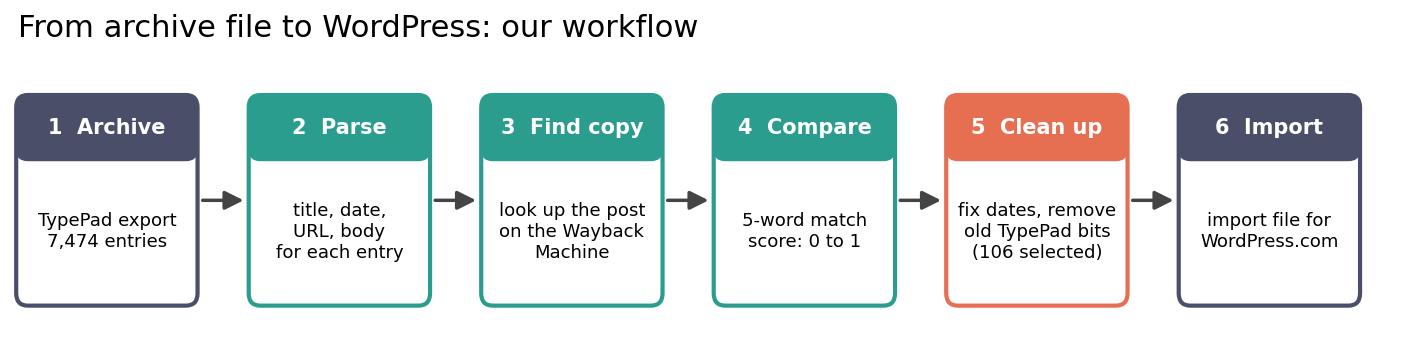

saved poster_figs/B_funnel.png and .svg


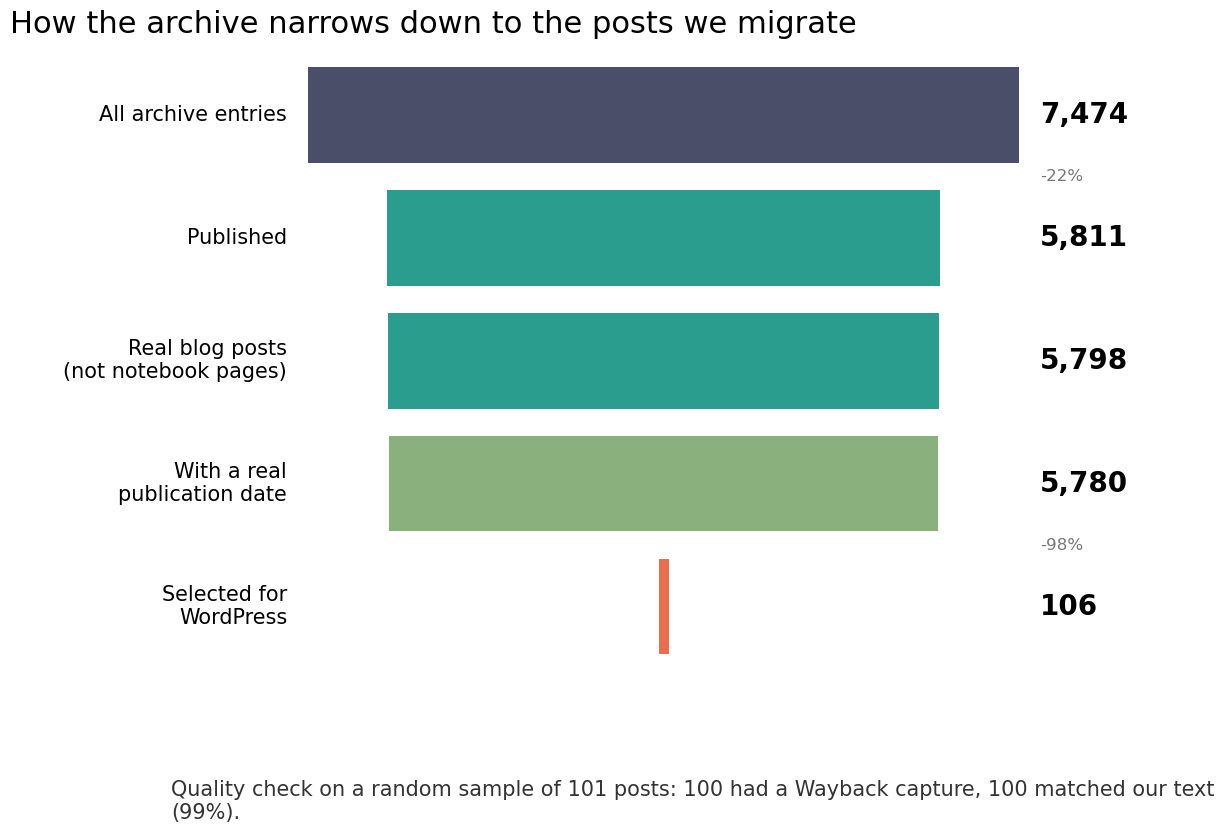

In [7]:
"""
NEW CELL: pipeline diagram + funnel chart for the poster.
Run AFTER the compare_entry.py cell (uses split_entries / parse_entry).
Optional inputs, used automatically if present:
  comparison_results.csv      (batch cell)    -> sample results shown on the funnel
  selected_posts_report.csv   (cleanup cell)  -> "selected for WordPress" count
 
Saves PNG (300 dpi) and SVG into poster_figs/.
"""
import os
import re
import datetime as dt
 
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
 
# ---------------------------------------------------------------- settings
ARCHIVE_FILE = "typepad_archives.txt"
RESULTS_CSV = "comparison_results.csv"
REPORT_CSV = "selected_posts_report.csv"
OUT_DIR = "poster_figs"
SELECTED_COUNT_OVERRIDE = None   # e.g. 100 if you don't have the report CSV yet
 
TEAL, GREEN, YELLOW, ORANGE, GREY, NAVY = "#2a9d8f", "#8ab17d", "#e9c46a", "#e76f51", "#8d99ae", "#4a4e69"
 
plt.rcParams.update({
    "font.size": 16, "axes.spines.top": False, "axes.spines.right": False,
    "savefig.dpi": 300, "savefig.bbox": "tight",
})
 
 
def save(fig, name):
    os.makedirs(OUT_DIR, exist_ok=True)
    for ext in ("png", "svg"):
        fig.savefig(os.path.join(OUT_DIR, f"{name}.{ext}"))
    print(f"saved {OUT_DIR}/{name}.png and .svg")
 
 
# ---------------------------------------------------------------- counts from the archive
with open(ARCHIVE_FILE, "r") as f:
    all_entries = split_entries(f.read())
parsed = [parse_entry(e) for e in all_entries]
 
def real_date(raw):
    for fmt in ("%m/%d/%Y %I:%M:%S %p", "%m/%d/%Y %H:%M:%S"):
        try:
            return dt.datetime.strptime(raw, fmt).year <= dt.date.today().year
        except ValueError:
            pass
    return False
 
n_all = len(parsed)
published = [p for p in parsed if p["status"].lower().startswith("publish")]
posts = [p for p in published if not p["title"].startswith("NOTEBOOK:")]
dated = [p for p in posts if real_date(p["date"])]
counts = {"all": n_all, "published": len(published), "posts": len(posts), "dated": len(dated)}
print(counts)
 
selected = SELECTED_COUNT_OVERRIDE
if selected is None and os.path.exists(REPORT_CSV):
    selected = len(pd.read_csv(REPORT_CSV))
 
sample_n = sample_ok = sample_cap = None
if os.path.exists(RESULTS_CSV):
    res = pd.read_csv(RESULTS_CSV)
    sample_n = len(res)
    sample_cap = int((~res["verdict"].astype(str).str.startswith(("NO CAPTURE", "ERROR"))).sum())
    sample_ok = int(res["verdict"].astype(str).str.startswith(("SAME", "LIKELY SAME")).sum())
 
 
# ---------------------------------------------------------------- Figure A: pipeline diagram
def fig_pipeline():
    steps = [
        ("1  Archive", f"TypePad export\n{counts['all']:,} entries", NAVY),
        ("2  Parse", "title, date,\nURL, body\nfor each entry", TEAL),
        ("3  Find copy", "look up the post\non the Wayback\nMachine", TEAL),
        ("4  Compare", "5-word match\nscore: 0 to 1", TEAL),
        ("5  Clean up", "fix dates, remove\nold TypePad bits" + (f"\n({selected} selected)" if selected else ""), ORANGE),
        ("6  Import", "import file for\nWordPress.com", NAVY),
    ]
    n = len(steps)
    fig, ax = plt.subplots(figsize=(18, 4.2))
    ax.set_xlim(0, n * 3.0)
    ax.set_ylim(0, 3.9)
    ax.axis("off")
    w, h, gap = 2.3, 2.5, 0.7
    for i, (head, body, color) in enumerate(steps):
        x = i * (w + gap) + 0.1
        ax.add_patch(FancyBboxPatch((x, 0.35), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                    fc="white", ec=color, lw=3))
        ax.add_patch(FancyBboxPatch((x, 0.35 + h - 0.75), w, 0.75,
                                    boxstyle="round,pad=0.02,rounding_size=0.15", fc=color, ec=color))
        ax.text(x + w / 2, 0.35 + h - 0.375, head, ha="center", va="center",
                color="white", fontsize=15, fontweight="bold")
        ax.text(x + w / 2, 0.35 + (h - 0.75) / 2, body, ha="center", va="center", fontsize=13)
        if i < n - 1:
            ax.add_patch(FancyArrowPatch((x + w + 0.05, 0.35 + h / 2), (x + w + gap - 0.05, 0.35 + h / 2),
                                         arrowstyle="-|>", mutation_scale=28, color="#444", lw=2.5))
    ax.text(0.1, 3.85, "From archive file to WordPress: our workflow", fontsize=22, va="top")
    return fig
 
 
# ---------------------------------------------------------------- Figure B: funnel
def fig_funnel():
    stages = [
        ("All archive entries", counts["all"], NAVY),
        ("Published", counts["published"], TEAL),
        ("Real blog posts\n(not notebook pages)", counts["posts"], TEAL),
        ("With a real\npublication date", counts["dated"], GREEN),
    ]
    if selected:
        stages.append(("Selected for\nWordPress", selected, ORANGE))
    labels = [s[0] for s in stages]
    vals = [s[1] for s in stages]
    top = max(vals)
 
    fig, ax = plt.subplots(figsize=(11, 1.3 * len(stages) + 1.8))
    for i, (lab, v, c) in enumerate(stages):
        width = max(v / top, 0.012)   # keep tiny stages visible
        ax.barh(i, width, left=(1 - width) / 2, height=0.78, color=c)   # centred, so it narrows like a funnel
        ax.text(1.03, i, f"{v:,}", va="center", fontsize=20, fontweight="bold")
        ax.text(-0.03, i, lab, va="center", ha="right", fontsize=15)
        if i > 0 and vals[i - 1]:
            drop = 1 - v / vals[i - 1]
            if drop > 0.005:
                ax.text(1.03, i - 0.5, f"-{drop:.0%}", va="center", fontsize=12, color="#777")
    ax.set_xlim(0, 1.2)
    ax.set_ylim(len(stages) - 0.4, -0.6)
    ax.axis("off")
    ax.set_title("How the archive narrows down to the posts we migrate", loc="left", fontsize=22, x=-0.35)
 
    if sample_n:
        txt = (f"Quality check on a random sample of {sample_n} posts: "
               f"{sample_cap} had a Wayback capture, {sample_ok} matched our text "
               f"({sample_ok / sample_n:.0%}).")
        fig.text(0.0, -0.01, txt, fontsize=15, color="#333", va="top", wrap=True)
    return fig
 
 
for name, fn in [("A_pipeline", fig_pipeline), ("B_funnel", fig_funnel)]:
    fig = fn()
    save(fig, name)
    plt.show()